# Ejercicios: Modelos de Regresion aplicados a datos demograficos

**Materia:** Topicos de Big Data  
**Tema:** Modelos de regresion supervisada - Ejercicios adicionales  
**Herramientas:** Python - Jupyter Notebook - Pandas - NumPy - Matplotlib - Scikit-learn  

---

## Objetivo

Aplicar los **tres modelos de regresion** sobre nuevos subconjuntos de datos:

1. **Ejercicio 1:** Extraer y analizar los datos de **China** (rango completo de anios disponibles).
2. **Ejercicio 2:** Extraer nacimientos y defunciones de **Mexico a partir del anio 2000**.

| Modelo | Abreviatura |
|---|---|
| Regresion Lineal | RL |
| Regresion Polinomial (grado 2) | RP |
| Random Forest Regressor | RF |

---

# PARTE 1. Importar bibliotecas y cargar el dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.ensemble import RandomForestRegressor

In [2]:
csv_path = "c:\\Users\\sebar\\Documents\\BIG_DATA_512\\U3_1_modelos_regresion_demografia\\U3_1_modelos_ml\\notebook\\births-and-deaths-projected-to-2100.csv"
df = pd.read_csv(csv_path)
print("Datos cargados desde archivo local:", csv_path)
df.head()

Datos cargados desde archivo local: c:\Users\sebar\Documents\BIG_DATA_512\U3_1_modelos_regresion_demografia\U3_1_modelos_ml\notebook\births-and-deaths-projected-to-2100.csv


,entity,code,year,deaths__sex_all__age_all__variant_estimates,deaths__sex_all__age_all__variant_medium__projected,births__sex_all__age_all__variant_estimates,births__sex_all__age_all__variant_medium__projected
0,Afghanistan,AFG,1950,290972.0,NaN,383985.0,NaN
1,Afghanistan,AFG,1951,288752.0,NaN,391002.0,NaN
2,Afghanistan,AFG,1952,288059.0,NaN,397663.0,NaN
3,Afghanistan,AFG,1953,287712.0,NaN,404666.0,NaN
4,Afghanistan,AFG,1954,289189.0,NaN,410428.0,NaN


In [3]:
df = df.rename(columns={
    "entity": "Entity",
    "code": "Code",
    "year": "Year",
    "births__sex_all__age_all__variant_estimates": "births_estimates",
    "births__sex_all__age_all__variant_medium__projected": "births_projected",
    "deaths__sex_all__age_all__variant_estimates": "deaths_estimates",
    "deaths__sex_all__age_all__variant_medium__projected": "deaths_projected",
})

df["births"] = df["births_estimates"].fillna(df["births_projected"])
df["deaths"] = df["deaths_estimates"].fillna(df["deaths_projected"])

print("Dimensiones:", df.shape)
df.head()

Dimensiones: (39562, 9)


,Entity,Code,Year,deaths_estimates,deaths_projected,births_estimates,births_projected,births,deaths
0,Afghanistan,AFG,1950,290972.0,NaN,383985.0,NaN,383985.0,290972.0
1,Afghanistan,AFG,1951,288752.0,NaN,391002.0,NaN,391002.0,288752.0
2,Afghanistan,AFG,1952,288059.0,NaN,397663.0,NaN,397663.0,288059.0
3,Afghanistan,AFG,1953,287712.0,NaN,404666.0,NaN,404666.0,287712.0
4,Afghanistan,AFG,1954,289189.0,NaN,410428.0,NaN,410428.0,289189.0


---

# EJERCICIO 1: China

## Paso 1. Extraer los datos de China

In [4]:
pais_china = "China"
df_china = df[df["Entity"] == pais_china].copy()

print("Rango de anios:", df_china["Year"].min(), "-", df_china["Year"].max())
print("Numero de filas:", df_china.shape[0])
df_china.head()

Rango de anios: 1950 - 2100
Numero de filas: 151


,Entity,Code,Year,deaths_estimates,deaths_projected,births_estimates,births_projected,births,deaths
7097,China,CHN,1950,12564023.0,NaN,22293376.0,NaN,22293376.0,12564023.0
7098,China,CHN,1951,12411701.0,NaN,22144814.0,NaN,22144814.0,12411701.0
7099,China,CHN,1952,12459848.0,NaN,25496318.0,NaN,25496318.0,12459848.0
7100,China,CHN,1953,12309525.0,NaN,24139416.0,NaN,24139416.0,12309525.0
7101,China,CHN,1954,12145578.0,NaN,25438544.0,NaN,25438544.0,12145578.0


## Paso 2. Exploracion visual - China

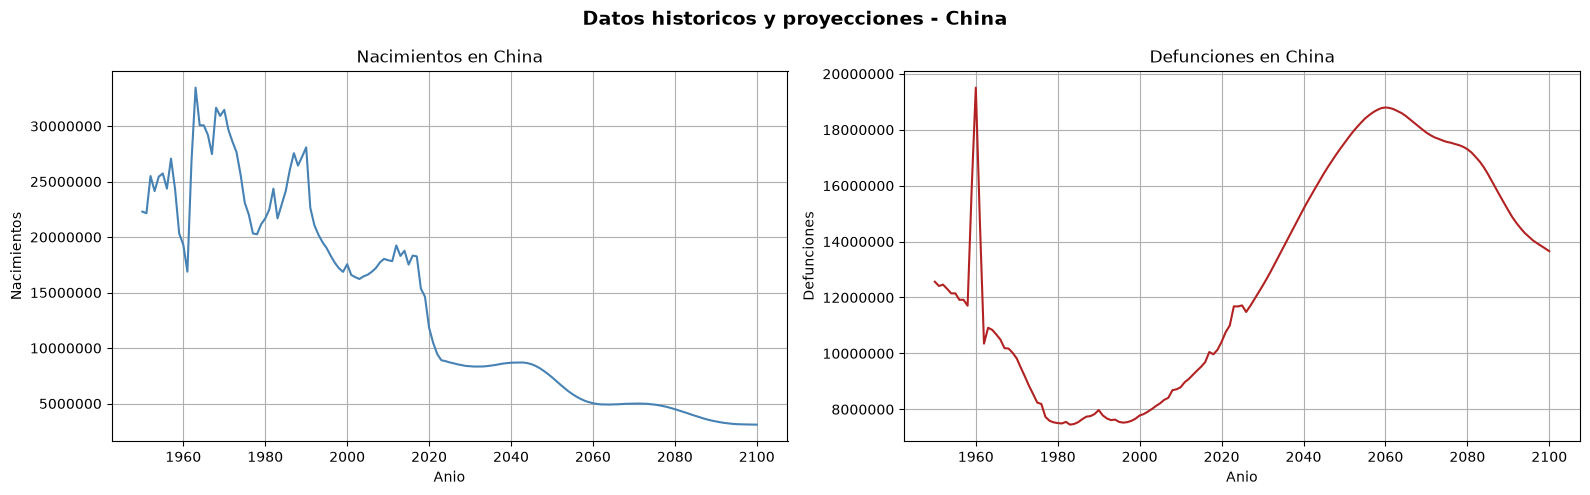

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

axes[0].plot(df_china["Year"], df_china["births"], color="steelblue")
axes[0].set_title("Nacimientos en China")
axes[0].set_xlabel("Anio")
axes[0].set_ylabel("Nacimientos")
axes[0].ticklabel_format(style="plain", axis="y", useOffset=False)
axes[0].grid(True)

axes[1].plot(df_china["Year"], df_china["deaths"], color="firebrick")
axes[1].set_title("Defunciones en China")
axes[1].set_xlabel("Anio")
axes[1].set_ylabel("Defunciones")
axes[1].ticklabel_format(style="plain", axis="y", useOffset=False)
axes[1].grid(True)

plt.suptitle("Datos historicos y proyecciones - China", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

## Paso 3. Separar historico y proyectado - China

In [6]:
df_china_hist = df_china[df_china["Year"] <= 2023].copy()
df_china_proy = df_china[df_china["Year"] > 2023].copy()

print("Historico  ->", df_china_hist.shape, "| anios:", df_china_hist["Year"].min(), "a", df_china_hist["Year"].max())
print("Proyectado ->", df_china_proy.shape, "| anios:", df_china_proy["Year"].min(), "a", df_china_proy["Year"].max())

Historico  -> (74, 9) | anios: 1950 a 2023
Proyectado -> (77, 9) | anios: 2024 a 2100


## Paso 4. Preparar variables para ML - China

In [7]:
X_china = df_china_hist[["Year"]]
y_china_births = df_china_hist["births"]
y_china_deaths = df_china_hist["deaths"]

anios_futuros_china = np.arange(2024, 2101).reshape(-1, 1)
X_futuro_china = pd.DataFrame(anios_futuros_china, columns=["Year"])

poly_china = PolynomialFeatures(degree=2, include_bias=False)
X_china_poly = poly_china.fit_transform(X_china)
X_futuro_china_poly = poly_china.transform(X_futuro_china)

print("X_china shape:", X_china.shape)

X_china shape: (74, 1)


## Paso 5. Entrenar los 3 modelos - Nacimientos en China

### RL, RP, RF

In [8]:
# Regresion Lineal
rl_china_births = LinearRegression()
rl_china_births.fit(X_china, y_china_births)
pred_rl_china_births_hist   = rl_china_births.predict(X_china)
pred_rl_china_births_futuro = rl_china_births.predict(X_futuro_china)

# Regresion Polinomial
rp_china_births = LinearRegression()
rp_china_births.fit(X_china_poly, y_china_births)
pred_rp_china_births_hist   = rp_china_births.predict(X_china_poly)
pred_rp_china_births_futuro = rp_china_births.predict(X_futuro_china_poly)

# Random Forest
rf_china_births = RandomForestRegressor(n_estimators=100, random_state=42)
rf_china_births.fit(X_china, y_china_births)
pred_rf_china_births_hist   = rf_china_births.predict(X_china)
pred_rf_china_births_futuro = rf_china_births.predict(X_futuro_china)

print("Modelos de nacimientos (China) entrenados correctamente")

Modelos de nacimientos (China) entrenados correctamente

## Paso 6. Graficas individuales - Nacimientos en China

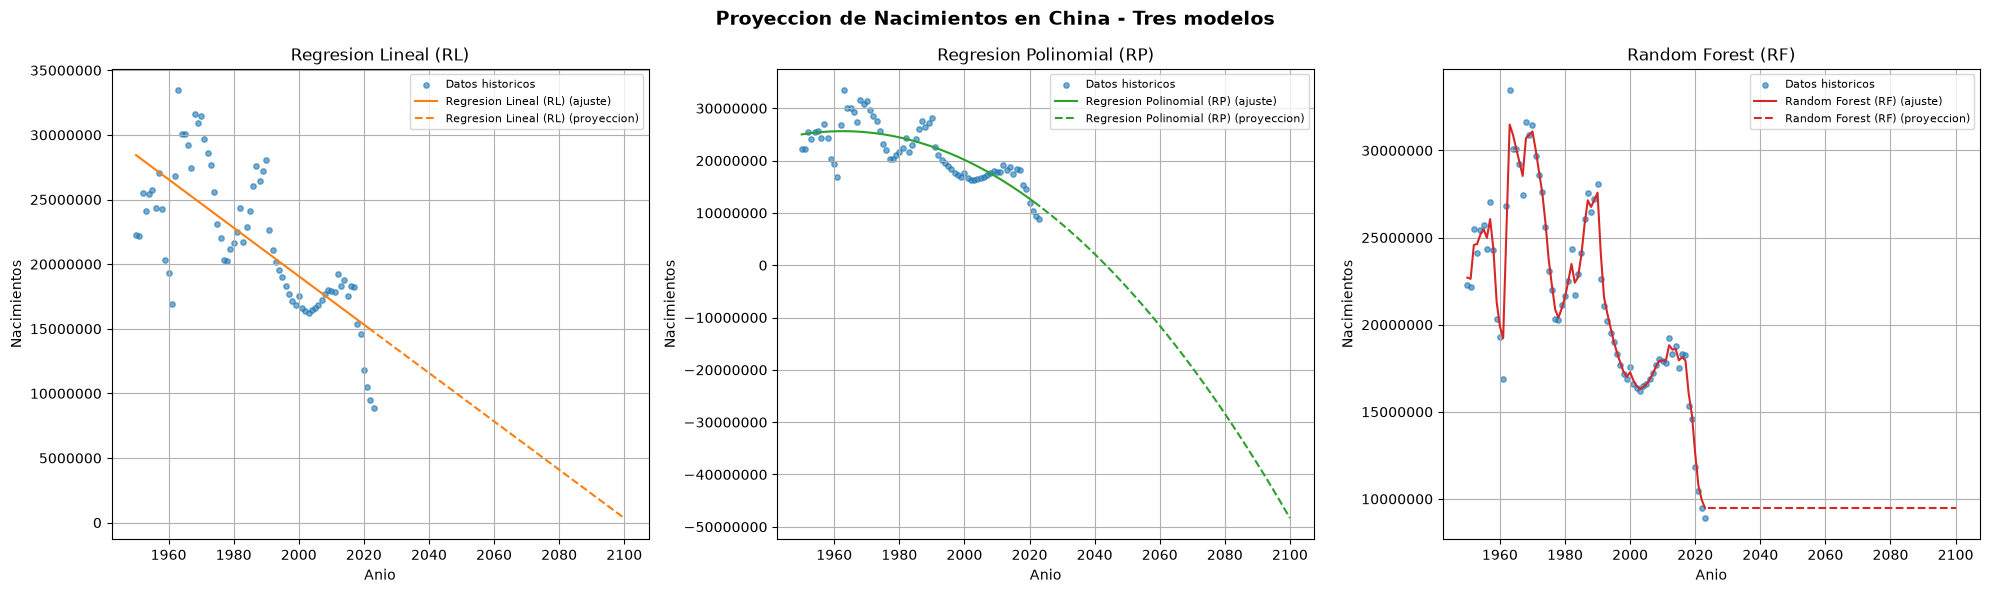

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

modelos_births_china = [
    ("Regresion Lineal (RL)",     "tab:orange", pred_rl_china_births_hist, pred_rl_china_births_futuro),
    ("Regresion Polinomial (RP)", "tab:green",  pred_rp_china_births_hist, pred_rp_china_births_futuro),
    ("Random Forest (RF)",        "tab:red",    pred_rf_china_births_hist, pred_rf_china_births_futuro),
]

for ax, (nombre, color, pred_hist, pred_fut) in zip(axes, modelos_births_china):
    ax.scatter(df_china_hist["Year"], df_china_hist["births"],
               label="Datos historicos", alpha=0.6, s=15)
    ax.plot(df_china_hist["Year"], pred_hist, color=color, label=f"{nombre} (ajuste)")
    ax.plot(anios_futuros_china.flatten(), pred_fut, color=color, linestyle="--",
            label=f"{nombre} (proyeccion)")
    ax.set_title(nombre)
    ax.set_xlabel("Anio")
    ax.set_ylabel("Nacimientos")
    ax.ticklabel_format(style="plain", axis="y", useOffset=False)
    ax.legend(fontsize=8)
    ax.grid(True)

plt.suptitle("Proyeccion de Nacimientos en China - Tres modelos", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

## Paso 7. Comparacion de los 3 modelos - Nacimientos en China

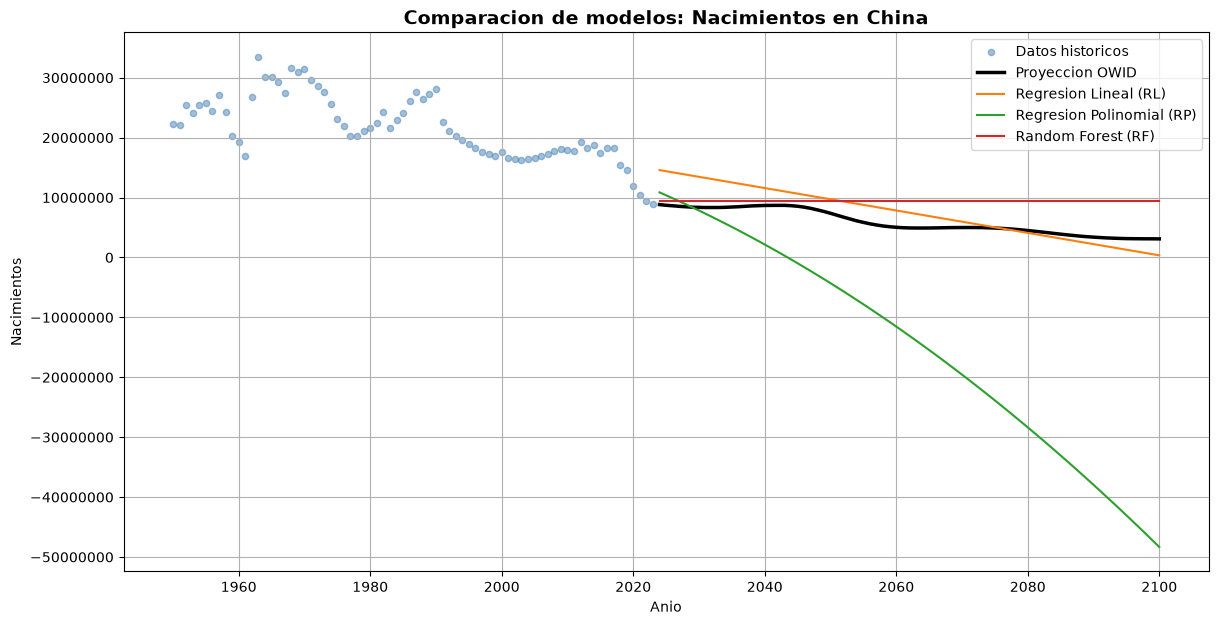

In [10]:
plt.figure(figsize=(14, 7))

plt.scatter(df_china_hist["Year"], df_china_hist["births"],
            label="Datos historicos", alpha=0.5, s=20, color="steelblue")
plt.plot(df_china_proy["Year"], df_china_proy["births"],
         color="black", linewidth=2.5, label="Proyeccion OWID")
plt.plot(anios_futuros_china.flatten(), pred_rl_china_births_futuro,
         color="tab:orange", label="Regresion Lineal (RL)")
plt.plot(anios_futuros_china.flatten(), pred_rp_china_births_futuro,
         color="tab:green", label="Regresion Polinomial (RP)")
plt.plot(anios_futuros_china.flatten(), pred_rf_china_births_futuro,
         color="tab:red", label="Random Forest (RF)")

plt.title("Comparacion de modelos: Nacimientos en China", fontsize=14, fontweight="bold")
plt.xlabel("Anio")
plt.ylabel("Nacimientos")
plt.ticklabel_format(style="plain", axis="y", useOffset=False)
plt.legend()
plt.grid(True)
plt.show()

## Paso 8. Entrenar los 3 modelos - Defunciones en China

In [11]:
# Regresion Lineal
rl_china_deaths = LinearRegression()
rl_china_deaths.fit(X_china, y_china_deaths)
pred_rl_china_deaths_hist   = rl_china_deaths.predict(X_china)
pred_rl_china_deaths_futuro = rl_china_deaths.predict(X_futuro_china)

# Regresion Polinomial
rp_china_deaths = LinearRegression()
rp_china_deaths.fit(X_china_poly, y_china_deaths)
pred_rp_china_deaths_hist   = rp_china_deaths.predict(X_china_poly)
pred_rp_china_deaths_futuro = rp_china_deaths.predict(X_futuro_china_poly)

# Random Forest
rf_china_deaths = RandomForestRegressor(n_estimators=100, random_state=42)
rf_china_deaths.fit(X_china, y_china_deaths)
pred_rf_china_deaths_hist   = rf_china_deaths.predict(X_china)
pred_rf_china_deaths_futuro = rf_china_deaths.predict(X_futuro_china)

print("Modelos de defunciones (China) entrenados correctamente")

Modelos de defunciones (China) entrenados correctamente


## Paso 9. Graficas individuales - Defunciones en China

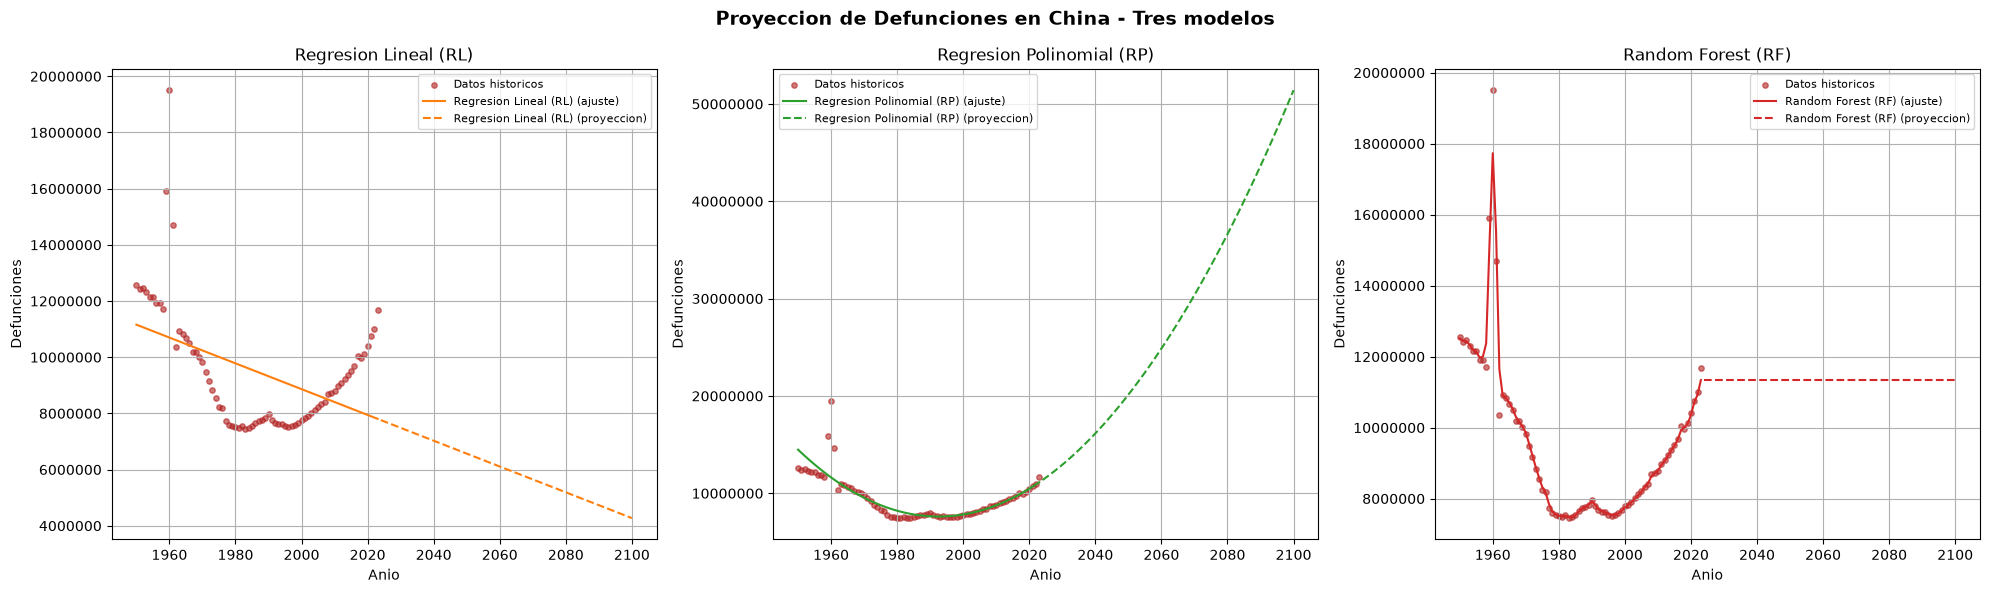

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

modelos_deaths_china = [
    ("Regresion Lineal (RL)",     "tab:orange", pred_rl_china_deaths_hist, pred_rl_china_deaths_futuro),
    ("Regresion Polinomial (RP)", "tab:green",  pred_rp_china_deaths_hist, pred_rp_china_deaths_futuro),
    ("Random Forest (RF)",        "tab:red",    pred_rf_china_deaths_hist, pred_rf_china_deaths_futuro),
]

for ax, (nombre, color, pred_hist, pred_fut) in zip(axes, modelos_deaths_china):
    ax.scatter(df_china_hist["Year"], df_china_hist["deaths"],
               label="Datos historicos", alpha=0.6, s=15, color="firebrick")
    ax.plot(df_china_hist["Year"], pred_hist, color=color, label=f"{nombre} (ajuste)")
    ax.plot(anios_futuros_china.flatten(), pred_fut, color=color, linestyle="--",
            label=f"{nombre} (proyeccion)")
    ax.set_title(nombre)
    ax.set_xlabel("Anio")
    ax.set_ylabel("Defunciones")
    ax.ticklabel_format(style="plain", axis="y", useOffset=False)
    ax.legend(fontsize=8)
    ax.grid(True)

plt.suptitle("Proyeccion de Defunciones en China - Tres modelos", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

## Paso 10. Comparacion de los 3 modelos - Defunciones en China

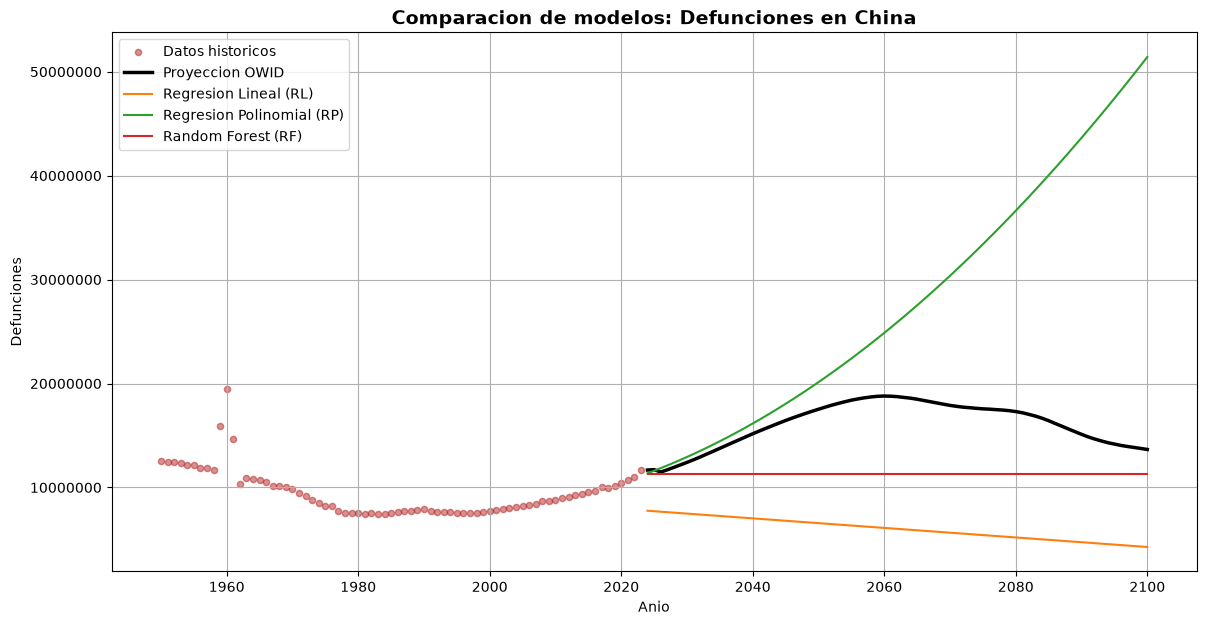

In [13]:
plt.figure(figsize=(14, 7))

plt.scatter(df_china_hist["Year"], df_china_hist["deaths"],
            label="Datos historicos", alpha=0.5, s=20, color="firebrick")
plt.plot(df_china_proy["Year"], df_china_proy["deaths"],
         color="black", linewidth=2.5, label="Proyeccion OWID")
plt.plot(anios_futuros_china.flatten(), pred_rl_china_deaths_futuro,
         color="tab:orange", label="Regresion Lineal (RL)")
plt.plot(anios_futuros_china.flatten(), pred_rp_china_deaths_futuro,
         color="tab:green", label="Regresion Polinomial (RP)")
plt.plot(anios_futuros_china.flatten(), pred_rf_china_deaths_futuro,
         color="tab:red", label="Random Forest (RF)")

plt.title("Comparacion de modelos: Defunciones en China", fontsize=14, fontweight="bold")
plt.xlabel("Anio")
plt.ylabel("Defunciones")
plt.ticklabel_format(style="plain", axis="y", useOffset=False)
plt.legend()
plt.grid(True)
plt.show()

## Paso 11. Tabla resumen - China (anios clave)

In [14]:
anios_tabla = [2030, 2050, 2075, 2100]
indice_china = anios_futuros_china.flatten()

def construir_tabla(df_proy, owid_col, lineal, polinomial, rf, indice):
    df_owid = df_proy.set_index("Year")[owid_col].reindex(indice)
    tabla = pd.DataFrame({
        "OWID": df_owid.values,
        "RL": lineal,
        "RP": polinomial,
        "RF": rf,
    }, index=indice)
    tabla.index.name = "Anio"
    return tabla.loc[anios_tabla]

print("NACIMIENTOS - China")
display(construir_tabla(df_china_proy, "births",
    pred_rl_china_births_futuro, pred_rp_china_births_futuro,
    pred_rf_china_births_futuro, indice_china).style.format("{:,.0f}"))

print("DEFUNCIONES - China")
display(construir_tabla(df_china_proy, "deaths",
    pred_rl_china_deaths_futuro, pred_rp_china_deaths_futuro,
    pred_rf_china_deaths_futuro, indice_china).style.format("{:,.0f}"))

NACIMIENTOS - China


,OWID,RL,RP,RF
Anio,,,,
2030,"8,359,513","13,456,651","7,830,199","9,489,420"
2050,"7,371,348","9,712,484","-4,298,790","9,489,420"
2075,"4,909,046","5,032,277","-23,867,936","9,489,420"
2100,"3,099,844","352,069","-48,334,758","9,489,420"


DEFUNCIONES - China


,OWID,RL,RP,RF
Anio,,,,
2030,"12,415,078","7,485,699","12,933,834","11,339,159"
2050,"17,526,300","6,567,577","20,134,799","11,339,159"
2075,"17,564,112","5,419,925","33,404,217","11,339,159"
2100,"13,655,445","4,272,272","51,416,093","11,339,159"


---

# EJERCICIO 2: Mexico - Nacimientos y Defunciones a partir del anio 2000

## Paso 1. Extraer los datos de Mexico desde 2000

In [15]:
anio_inicio = 2000
df_mexico_2000 = df[(df["Entity"] == "Mexico") & (df["Year"] >= anio_inicio)].copy()

print("Rango de anios:", df_mexico_2000["Year"].min(), "-", df_mexico_2000["Year"].max())
print("Numero de filas:", df_mexico_2000.shape[0])
df_mexico_2000.head()

Rango de anios: 2000 - 2100
Numero de filas: 101


,Entity,Code,Year,deaths_estimates,deaths_projected,births_estimates,births_projected,births,deaths
22851,Mexico,MEX,2000,540567.0,NaN,2385977.0,NaN,2385977.0,540567.0
22852,Mexico,MEX,2001,543803.0,NaN,2380261.0,NaN,2380261.0,543803.0
22853,Mexico,MEX,2002,553391.0,NaN,2374140.0,NaN,2374140.0,553391.0
22854,Mexico,MEX,2003,563140.0,NaN,2351177.0,NaN,2351177.0,563140.0
22855,Mexico,MEX,2004,575925.0,NaN,2335226.0,NaN,2335226.0,575925.0


## Paso 2. Exploracion visual - Mexico desde 2000

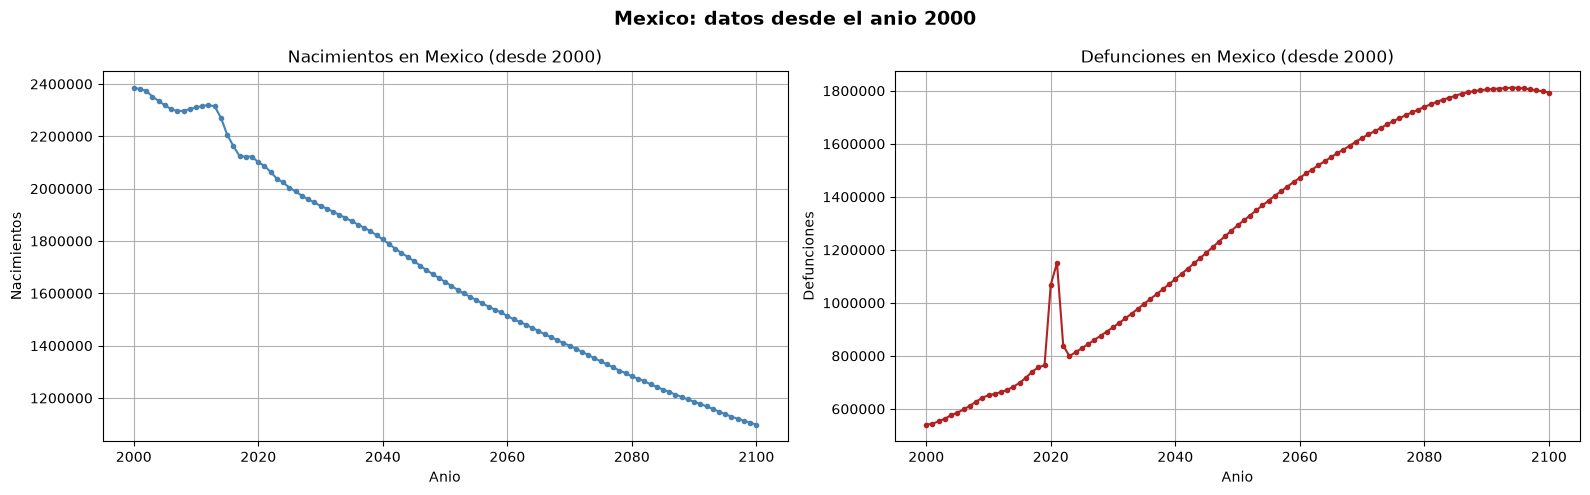

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

axes[0].plot(df_mexico_2000["Year"], df_mexico_2000["births"],
             color="steelblue", marker="o", markersize=3)
axes[0].set_title("Nacimientos en Mexico (desde 2000)")
axes[0].set_xlabel("Anio")
axes[0].set_ylabel("Nacimientos")
axes[0].ticklabel_format(style="plain", axis="y", useOffset=False)
axes[0].grid(True)

axes[1].plot(df_mexico_2000["Year"], df_mexico_2000["deaths"],
             color="firebrick", marker="o", markersize=3)
axes[1].set_title("Defunciones en Mexico (desde 2000)")
axes[1].set_xlabel("Anio")
axes[1].set_ylabel("Defunciones")
axes[1].ticklabel_format(style="plain", axis="y", useOffset=False)
axes[1].grid(True)

plt.suptitle("Mexico: datos desde el anio 2000", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

## Paso 3. Separar historico y proyectado - Mexico desde 2000

In [17]:
df_mex_hist = df_mexico_2000[df_mexico_2000["Year"] <= 2023].copy()
df_mex_proy = df_mexico_2000[df_mexico_2000["Year"] > 2023].copy()

print("Historico  ->", df_mex_hist.shape, "| anios:", df_mex_hist["Year"].min(), "a", df_mex_hist["Year"].max())
print("Proyectado ->", df_mex_proy.shape, "| anios:", df_mex_proy["Year"].min(), "a", df_mex_proy["Year"].max())
print("\nValores faltantes:")
print(df_mex_hist[["Year", "births", "deaths"]].isna().sum())

Historico  -> (24, 9) | anios: 2000 a 2023
Proyectado -> (77, 9) | anios: 2024 a 2100

Valores faltantes:
Year      0
births    0
deaths    0
dtype: int64


## Paso 4. Preparar variables para ML - Mexico desde 2000

In [18]:
X_mex = df_mex_hist[["Year"]]
y_mex_births = df_mex_hist["births"]
y_mex_deaths = df_mex_hist["deaths"]

anios_futuros_mex = np.arange(2024, 2101).reshape(-1, 1)
X_futuro_mex = pd.DataFrame(anios_futuros_mex, columns=["Year"])

poly_mex = PolynomialFeatures(degree=2, include_bias=False)
X_mex_poly = poly_mex.fit_transform(X_mex)
X_futuro_mex_poly = poly_mex.transform(X_futuro_mex)

print("X_mex shape:", X_mex.shape)
print("X_mex_poly shape:", X_mex_poly.shape)

X_mex shape: (24, 1)
X_mex_poly shape: (24, 2)


## Paso 5. Entrenar los 3 modelos - Nacimientos en Mexico (desde 2000)

In [19]:
# Regresion Lineal
rl_mex_births = LinearRegression()
rl_mex_births.fit(X_mex, y_mex_births)
pred_rl_mex_births_hist   = rl_mex_births.predict(X_mex)
pred_rl_mex_births_futuro = rl_mex_births.predict(X_futuro_mex)
print("RL - Pendiente:", round(rl_mex_births.coef_[0], 2))

# Regresion Polinomial
rp_mex_births = LinearRegression()
rp_mex_births.fit(X_mex_poly, y_mex_births)
pred_rp_mex_births_hist   = rp_mex_births.predict(X_mex_poly)
pred_rp_mex_births_futuro = rp_mex_births.predict(X_futuro_mex_poly)

# Random Forest
rf_mex_births = RandomForestRegressor(n_estimators=100, random_state=42)
rf_mex_births.fit(X_mex, y_mex_births)
pred_rf_mex_births_hist   = rf_mex_births.predict(X_mex)
pred_rf_mex_births_futuro = rf_mex_births.predict(X_futuro_mex)

print("Tres modelos (nacimientos Mexico desde 2000) entrenados correctamente")

RL - Pendiente: -14819.75
Tres modelos (nacimientos Mexico desde 2000) entrenados correctamente


## Paso 6. Graficas individuales - Nacimientos en Mexico (desde 2000)

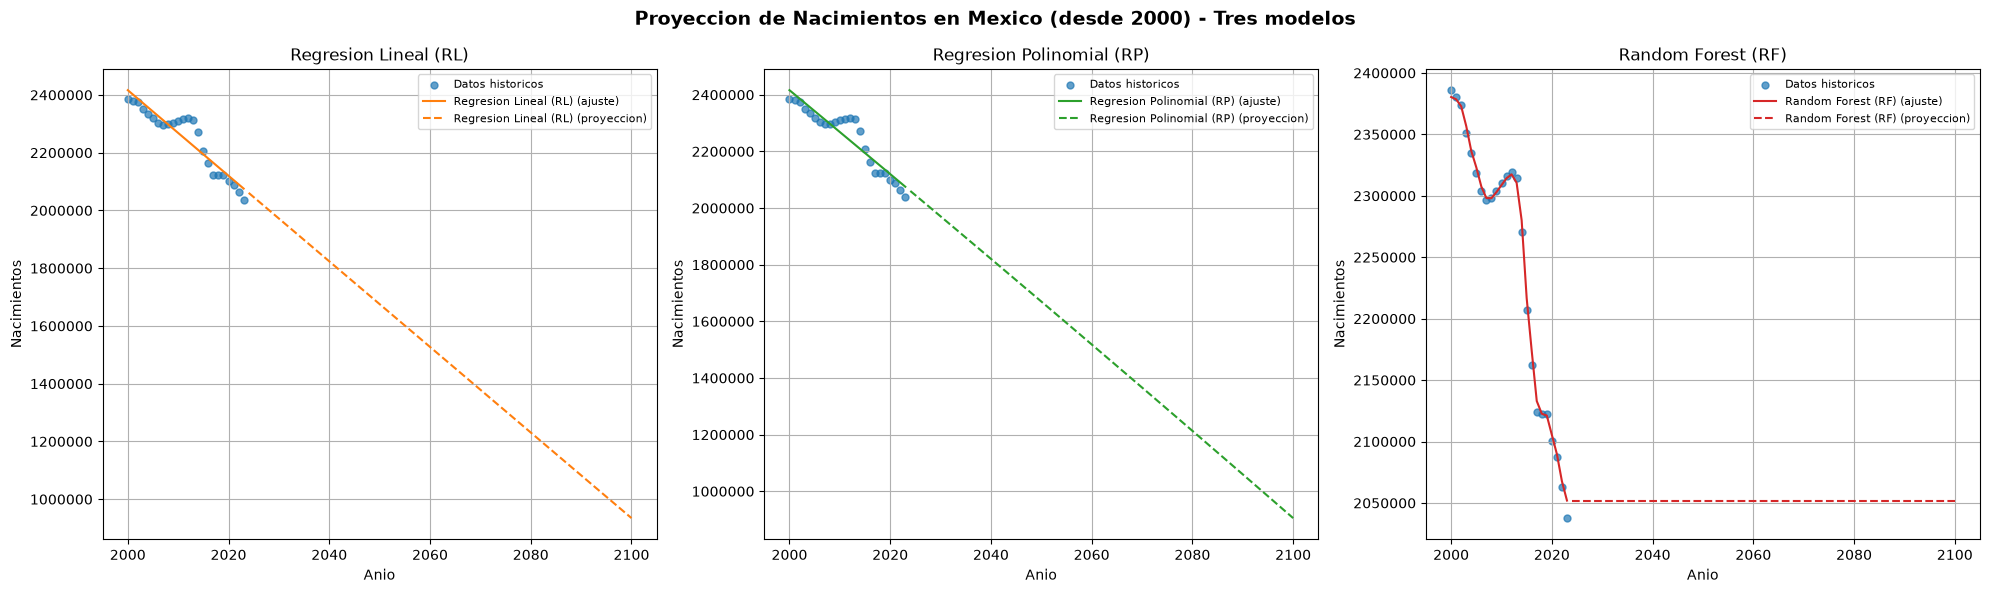

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

modelos_births_mex = [
    ("Regresion Lineal (RL)",     "tab:orange", pred_rl_mex_births_hist, pred_rl_mex_births_futuro),
    ("Regresion Polinomial (RP)", "tab:green",  pred_rp_mex_births_hist, pred_rp_mex_births_futuro),
    ("Random Forest (RF)",        "tab:red",    pred_rf_mex_births_hist, pred_rf_mex_births_futuro),
]

for ax, (nombre, color, pred_hist, pred_fut) in zip(axes, modelos_births_mex):
    ax.scatter(df_mex_hist["Year"], df_mex_hist["births"],
               label="Datos historicos", alpha=0.7, s=25)
    ax.plot(df_mex_hist["Year"], pred_hist, color=color, label=f"{nombre} (ajuste)")
    ax.plot(anios_futuros_mex.flatten(), pred_fut, color=color, linestyle="--",
            label=f"{nombre} (proyeccion)")
    ax.set_title(nombre)
    ax.set_xlabel("Anio")
    ax.set_ylabel("Nacimientos")
    ax.ticklabel_format(style="plain", axis="y", useOffset=False)
    ax.legend(fontsize=8)
    ax.grid(True)

plt.suptitle("Proyeccion de Nacimientos en Mexico (desde 2000) - Tres modelos",
             fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

## Paso 7. Comparacion de los 3 modelos - Nacimientos en Mexico (desde 2000)

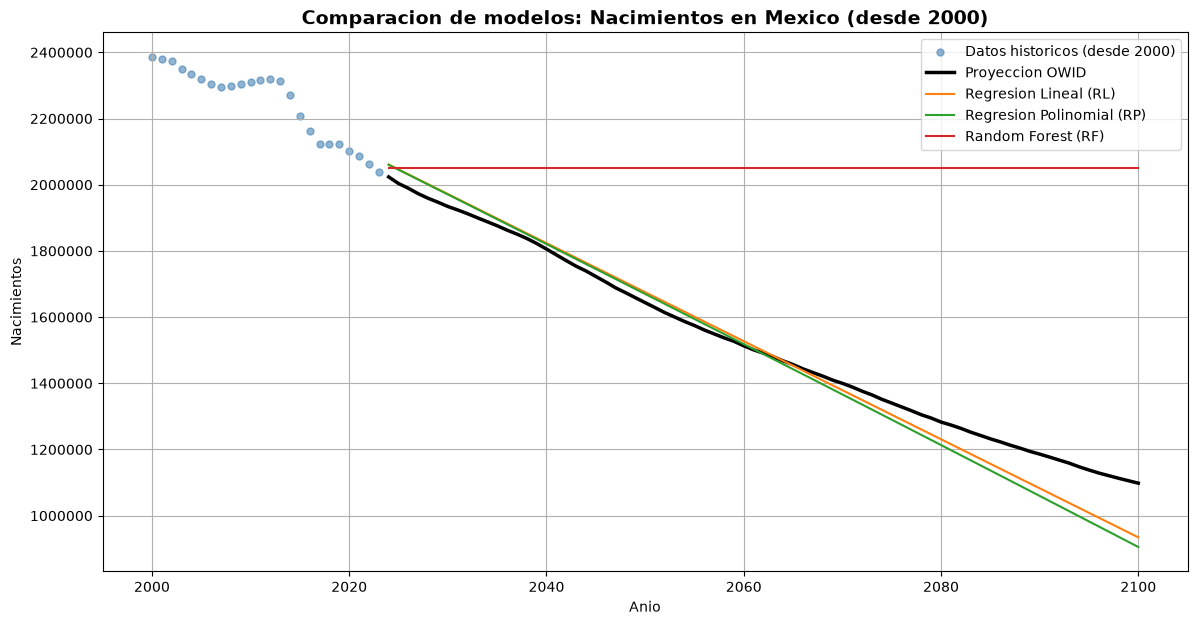

In [21]:
plt.figure(figsize=(14, 7))

plt.scatter(df_mex_hist["Year"], df_mex_hist["births"],
            label="Datos historicos (desde 2000)", alpha=0.6, s=25, color="steelblue")
plt.plot(df_mex_proy["Year"], df_mex_proy["births"],
         color="black", linewidth=2.5, label="Proyeccion OWID")
plt.plot(anios_futuros_mex.flatten(), pred_rl_mex_births_futuro,
         color="tab:orange", label="Regresion Lineal (RL)")
plt.plot(anios_futuros_mex.flatten(), pred_rp_mex_births_futuro,
         color="tab:green", label="Regresion Polinomial (RP)")
plt.plot(anios_futuros_mex.flatten(), pred_rf_mex_births_futuro,
         color="tab:red", label="Random Forest (RF)")

plt.title("Comparacion de modelos: Nacimientos en Mexico (desde 2000)",
          fontsize=14, fontweight="bold")
plt.xlabel("Anio")
plt.ylabel("Nacimientos")
plt.ticklabel_format(style="plain", axis="y", useOffset=False)
plt.legend()
plt.grid(True)
plt.show()

## Paso 8. Entrenar los 3 modelos - Defunciones en Mexico (desde 2000)

In [22]:
# Regresion Lineal
rl_mex_deaths = LinearRegression()
rl_mex_deaths.fit(X_mex, y_mex_deaths)
pred_rl_mex_deaths_hist   = rl_mex_deaths.predict(X_mex)
pred_rl_mex_deaths_futuro = rl_mex_deaths.predict(X_futuro_mex)

# Regresion Polinomial
rp_mex_deaths = LinearRegression()
rp_mex_deaths.fit(X_mex_poly, y_mex_deaths)
pred_rp_mex_deaths_hist   = rp_mex_deaths.predict(X_mex_poly)
pred_rp_mex_deaths_futuro = rp_mex_deaths.predict(X_futuro_mex_poly)

# Random Forest
rf_mex_deaths = RandomForestRegressor(n_estimators=100, random_state=42)
rf_mex_deaths.fit(X_mex, y_mex_deaths)
pred_rf_mex_deaths_hist   = rf_mex_deaths.predict(X_mex)
pred_rf_mex_deaths_futuro = rf_mex_deaths.predict(X_futuro_mex)

print("Tres modelos (defunciones Mexico desde 2000) entrenados correctamente")

Tres modelos (defunciones Mexico desde 2000) entrenados correctamente


## Paso 9. Graficas individuales - Defunciones en Mexico (desde 2000)

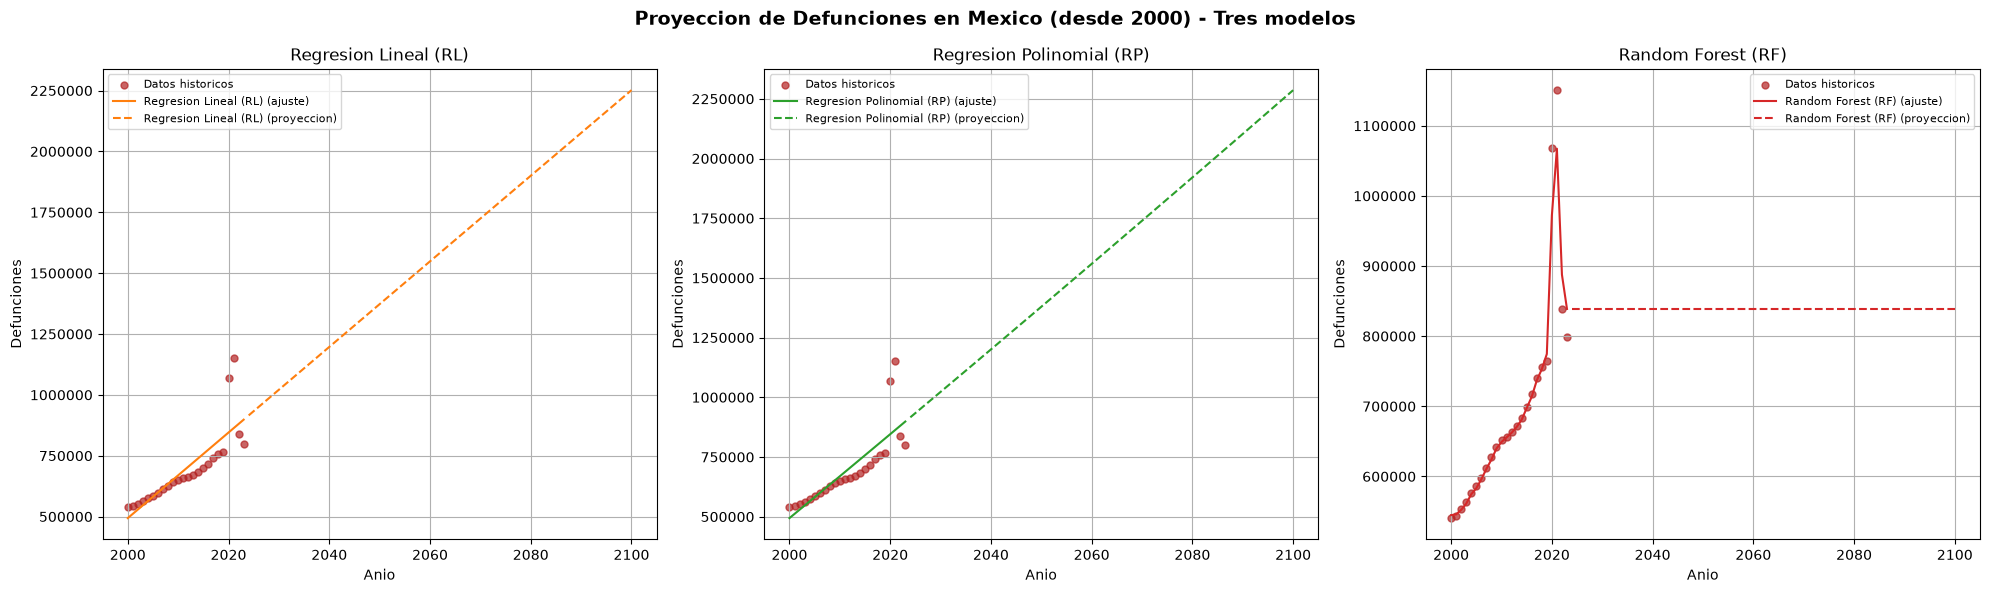

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

modelos_deaths_mex = [
    ("Regresion Lineal (RL)",     "tab:orange", pred_rl_mex_deaths_hist, pred_rl_mex_deaths_futuro),
    ("Regresion Polinomial (RP)", "tab:green",  pred_rp_mex_deaths_hist, pred_rp_mex_deaths_futuro),
    ("Random Forest (RF)",        "tab:red",    pred_rf_mex_deaths_hist, pred_rf_mex_deaths_futuro),
]

for ax, (nombre, color, pred_hist, pred_fut) in zip(axes, modelos_deaths_mex):
    ax.scatter(df_mex_hist["Year"], df_mex_hist["deaths"],
               label="Datos historicos", alpha=0.7, s=25, color="firebrick")
    ax.plot(df_mex_hist["Year"], pred_hist, color=color, label=f"{nombre} (ajuste)")
    ax.plot(anios_futuros_mex.flatten(), pred_fut, color=color, linestyle="--",
            label=f"{nombre} (proyeccion)")
    ax.set_title(nombre)
    ax.set_xlabel("Anio")
    ax.set_ylabel("Defunciones")
    ax.ticklabel_format(style="plain", axis="y", useOffset=False)
    ax.legend(fontsize=8)
    ax.grid(True)

plt.suptitle("Proyeccion de Defunciones en Mexico (desde 2000) - Tres modelos",
             fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

## Paso 10. Comparacion de los 3 modelos - Defunciones en Mexico (desde 2000)

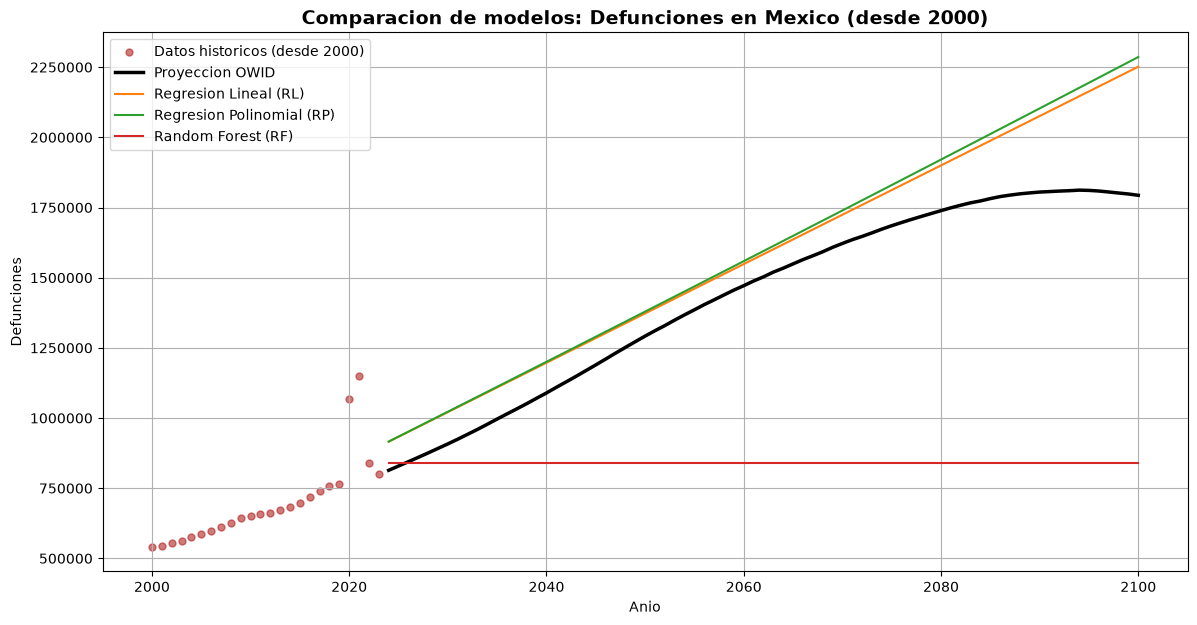

In [24]:
plt.figure(figsize=(14, 7))

plt.scatter(df_mex_hist["Year"], df_mex_hist["deaths"],
            label="Datos historicos (desde 2000)", alpha=0.6, s=25, color="firebrick")
plt.plot(df_mex_proy["Year"], df_mex_proy["deaths"],
         color="black", linewidth=2.5, label="Proyeccion OWID")
plt.plot(anios_futuros_mex.flatten(), pred_rl_mex_deaths_futuro,
         color="tab:orange", label="Regresion Lineal (RL)")
plt.plot(anios_futuros_mex.flatten(), pred_rp_mex_deaths_futuro,
         color="tab:green", label="Regresion Polinomial (RP)")
plt.plot(anios_futuros_mex.flatten(), pred_rf_mex_deaths_futuro,
         color="tab:red", label="Random Forest (RF)")

plt.title("Comparacion de modelos: Defunciones en Mexico (desde 2000)",
          fontsize=14, fontweight="bold")
plt.xlabel("Anio")
plt.ylabel("Defunciones")
plt.ticklabel_format(style="plain", axis="y", useOffset=False)
plt.legend()
plt.grid(True)
plt.show()

## Paso 11. Tabla resumen - Mexico desde 2000 (anios clave)

In [25]:
anios_tabla = [2030, 2050, 2075, 2100]
indice_mex = anios_futuros_mex.flatten()

print("NACIMIENTOS - Mexico (desde 2000)")
display(construir_tabla(df_mex_proy, "births",
    pred_rl_mex_births_futuro, pred_rp_mex_births_futuro,
    pred_rf_mex_births_futuro, indice_mex).style.format("{:,.0f}"))

print("DEFUNCIONES - Mexico (desde 2000)")
display(construir_tabla(df_mex_proy, "deaths",
    pred_rl_mex_deaths_futuro, pred_rp_mex_deaths_futuro,
    pred_rf_mex_deaths_futuro, indice_mex).style.format("{:,.0f}"))

NACIMIENTOS - Mexico (desde 2000)


,OWID,RL,RP,RF
Anio,,,,
2030,"1,934,285","1,971,876","1,970,689","2,051,955"
2050,"1,643,767","1,675,481","1,669,982","2,051,955"
2075,"1,340,246","1,304,988","1,289,953","2,051,955"
2100,"1,098,210","934,494","905,317","2,051,955"


DEFUNCIONES - Mexico (desde 2000)


,OWID,RL,RP,RF
Anio,,,,
2030,"907,843","1,021,129","1,022,528","838,793"
2050,"1,291,889","1,372,705","1,379,209","838,793"
2075,"1,685,181","1,812,175","1,829,978","838,793"
2100,"1,793,462","2,251,646","2,286,211","838,793"


---

# REFLEXION FINAL

### 1. China vs Mexico
Que diferencias observas en el comportamiento de los nacimientos y defunciones entre China y Mexico?

*Respuesta:*

### 2. Efecto del recorte de datos (Mexico desde 2000)
Como afecta el hecho de entrenar con datos solo desde el anio 2000 a la calidad de las proyecciones?

*Respuesta:*

### 3. Modelo mas adecuado
Que modelo (RL, RP o RF) parece ajustarse mejor a los datos historicos en cada caso?

*Respuesta:*

### 4. Limitaciones
Que limitaciones identificas al aplicar estos modelos para proyectar datos demograficos a largo plazo?

*Respuesta:*

---

# Conceptos clave

| Concepto | Significado |
|---|---|
| **Filtrado de datos** | Seleccionar filas del DataFrame que cumplen una condicion (pais, rango de anios) |
| **Variable predictora** | Variable utilizada por el modelo para generar una prediccion (Year) |
| **Variable objetivo** | Variable que queremos predecir (births o deaths) |
| **Regresion Lineal (RL)** | Modelo que representa una relacion lineal entre X e y |
| **Regresion Polinomial (RP)** | Extension que permite representar relaciones curvas (grado 2) |
| **Random Forest (RF)** | Modelo basado en multiples arboles de decision |
| **Extrapolacion** | Predicciones fuera del rango de datos de entrenamiento |

> **Nota:** Este notebook es complementario a la practica principal. Los modelos aplicados no han sido evaluados mediante metricas de desempeno.